# Практическая работа № 7. Случайный лес

**Уровень:** B (данные заданы)
**Цель:** обучить ансамблевую модель (случайный лес), сравнить её с одиночным деревом, настроить гиперпараметры с кросс-валидацией и проанализировать важность признаков.

**Данные:** `data/housing.csv` — задача регрессии, цена квартиры `price_kusd` (тыс. $), те же очистка, разбиение и пайплайн, что в ПР-3 и ПР-4 (для честного сравнения моделей).

In [1]:
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split, GridSearchCV, cross_val_score, KFold
from sklearn.pipeline import Pipeline
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

sys.path.append("../src")
from preprocessing import clean_raw, build_preprocessor, NUM_COLS, CAT_COLS, TARGET

df = clean_raw(pd.read_csv("../data/housing.csv"))
X, y = df.drop(columns=TARGET), df[TARGET]
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)   # то же разбиение, что в ПР-3 и ПР-4
print("train:", X_train.shape, "| test:", X_test.shape)

def metrics(model, name):
    pred = model.predict(X_test)
    return {"модель": name, "MAE, тыс. $": mean_absolute_error(y_test, pred),
            "RMSE, тыс. $": np.sqrt(mean_squared_error(y_test, pred)), "R²": r2_score(y_test, pred)}

def make_pipe(model, num=NUM_COLS, cat=CAT_COLS):
    return Pipeline([("prep", build_preprocessor(num, cat)), ("model", model)])

train: (800, 10) | test: (200, 10)


## 1. Одиночное дерево против случайного леса (параметры по умолчанию)
Обе модели обучены на **одних и тех же** train/test с одним и тем же пайплайном предобработки. Для леса взято `n_estimators=100` (обоснование числа деревьев — в разделе 3).

In [2]:
tree = make_pipe(DecisionTreeRegressor(random_state=42)).fit(X_train, y_train)
rf_default = make_pipe(RandomForestRegressor(n_estimators=100, random_state=42, oob_score=True)).fit(X_train, y_train)
linear = make_pipe(LinearRegression()).fit(X_train, y_train)

table1 = pd.DataFrame([metrics(tree, "Одиночное дерево (без ограничений)"),
                       metrics(rf_default, "Случайный лес (100 деревьев, по умолчанию)"),
                       metrics(linear, "Линейная регрессия на всех признаках (для сравнения)")]).set_index("модель").round(3)
table1

                                                    MAE, тыс. $  RMSE, тыс. $     R²
модель                                                                              
Одиночное дерево (без ограничений)                       13.077        16.698  0.756
Случайный лес (100 деревьев, по умолчанию)               10.646        13.528  0.840
Линейная регрессия на всех признаках (для сравн...        8.803        10.920  0.895

In [3]:
print("Train R²: дерево =", round(tree.score(X_train, y_train), 3), "| лес =", round(rf_default.score(X_train, y_train), 3))
print("Test  R²: дерево =", round(tree.score(X_test, y_test), 3), "| лес =", round(rf_default.score(X_test, y_test), 3))
print("OOB R² леса (оценка без test):", round(rf_default.named_steps["model"].oob_score_, 3))

Train R²: дерево = 1.0 | лес = 0.977
Test  R²: дерево = 0.756 | лес = 0.84
OOB R² леса (оценка без test): 0.837


**Сравнение дерева и леса (test; MAE и RMSE — в тыс. $):**

| Модель | MAE | RMSE | R² |
|---|---|---|---|
| Одиночное дерево | 13,1 | 16,7 | 0,756 |
| Случайный лес (100 деревьев) | **10,6** | **13,5** | **0,840** |
| Линейная регрессия на всех признаках | 8,8 | 10,9 | 0,895 |

- **Одиночное дерево переобучается:** на train R² = 1,0 (оно запомнило обучающие данные), а на test всего 0,756 — это высокий *разброс* (variance). Лес усредняет 100 деревьев, обученных на разных bootstrap-выборках и разных подмножествах признаков, поэтому разброс падает: на test R² = 0,84, а средняя ошибка снизилась с 13,1 до 10,6 тыс. $. Это и есть смысл бэггинга.
- **OOB-оценка** леса (R² = 0,837) почти совпадает с оценкой на test (0,840) — то есть качество можно честно оценить даже без отдельной тестовой выборки: каждое дерево проверяется на объектах, которые не попали в его bootstrap-выборку.
- **Линейная регрессия оказалась лучше леса** (MAE 8,8 против 10,6). Это не ошибка: в этом синтетическом датасете цена задана *линейной* формулой плюс шум, а лес приближает прямую «ступеньками» и на 800 объектах делает это хуже. На реальных данных с нелинейными зависимостями и взаимодействиями признаков обычно выигрывает лес; сравнивать с простой базовой моделью нужно всегда. (Отметим также: эта линейная модель использует все признаки, включая три «дублирующих» признака площади, поэтому она точнее модели №3 из ПР-4 — это согласуется с выводом ПР-4 о том, что избыточные признаки площади помогают предсказанию, но мешают интерпретации.)

## 2. Настройка гиперпараметров (кросс-валидация)
Перебираем `n_estimators`, `max_depth`, `min_samples_leaf` по сетке с 5-кратной кросс-валидацией **только на train** (test остаётся нетронутым). Метрика отбора — MAE (в тыс. $).

In [4]:
param_grid = {
    "model__n_estimators": [50, 100, 300],
    "model__max_depth": [None, 5, 10, 20],
    "model__min_samples_leaf": [1, 3, 5, 10],
}
search = GridSearchCV(make_pipe(RandomForestRegressor(random_state=42)), param_grid,
                      cv=KFold(5, shuffle=True, random_state=42),
                      scoring="neg_mean_absolute_error", n_jobs=-1)
search.fit(X_train, y_train)

print("Лучшие параметры:", search.best_params_)
print("CV MAE лучшей модели:", round(-search.best_score_, 3), "тыс. $")
cvres = pd.DataFrame(search.cv_results_)
cols = ["param_model__n_estimators", "param_model__max_depth", "param_model__min_samples_leaf", "mean_test_score"]
top = cvres[cols].assign(CV_MAE=lambda d: -d["mean_test_score"]).sort_values("CV_MAE").head(8).drop(columns="mean_test_score")
top.columns = ["n_estimators", "max_depth", "min_samples_leaf", "CV MAE"]
top.round(3)

Лучшие параметры: {'model__max_depth': 10, 'model__min_samples_leaf': 3, 'model__n_estimators': 300}
CV MAE лучшей модели: 10.143 тыс. $


    n_estimators max_depth  min_samples_leaf  CV MAE
29           300        10                 3  10.143
5            300      None                 3  10.156
41           300        20                 3  10.156
27            50        10                 3  10.175
26           300        10                 1  10.178
3             50      None                 3  10.181
39            50        20                 3  10.181
28           100        10                 3  10.186

**Что показал перебор.** Лучшая комбинация: `n_estimators=300`, `max_depth=10`, `min_samples_leaf=3` (CV MAE ≈ 10,14 тыс. $). Графики (усреднение по остальным параметрам; обратите внимание на масштаб оси Y):
- `min_samples_leaf`: значения 1, 3, 5 дают почти одинаковую ошибку (≈ 10,3–10,4), а `min_samples_leaf=10` заметно хуже (≈ 10,9): слишком крупные листья — модель недообучается и теряет детали.
- `max_depth`: ограничение 5 ухудшает качество (≈ 10,9), а 10, 20 и «без ограничения» одинаковы (≈ 10,4) — очень глубокие ветви ничего не добавляют.
- `n_estimators`: разница между 50, 100 и 300 деревьями — сотые доли тыс. $ (ось Y на этом графике растянута), то есть число деревьев почти не влияет на качество в этом диапазоне.
Итог: умеренные значения параметров практически равноценны, а качество портят лишь слишком сильные ограничения.

param_model__max_depth
10          10.38
20          10.39
5           10.87
без огр.    10.39
Name: CV_MAE, dtype: float64


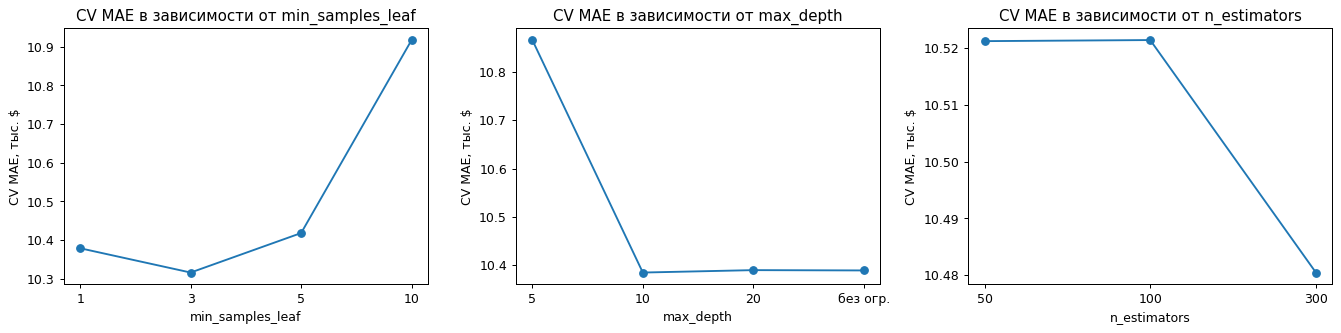

In [5]:
# Как каждый гиперпараметр влияет на CV MAE (усреднено по остальным параметрам)
cvres["CV_MAE"] = -cvres["mean_test_score"]
fig, axes = plt.subplots(1, 3, figsize=(15, 3.8))
for ax, p, title in zip(axes, ["param_model__min_samples_leaf", "param_model__max_depth", "param_model__n_estimators"],
                        ["min_samples_leaf", "max_depth", "n_estimators"]):
    labels = cvres[p].map(lambda v: "без огр." if v is None or (isinstance(v, float) and np.isnan(v)) else str(int(v)))
    g = cvres.groupby(labels)["CV_MAE"].mean()
    order_ = sorted([x for x in g.index if x != "без огр."], key=int) + (["без огр."] if "без огр." in g.index else [])
    ax.plot(order_, g[order_].values, marker="o")
    ax.set_title(f"CV MAE в зависимости от {title}")
    ax.set_xlabel(title)
    ax.set_ylabel("CV MAE, тыс. $")
plt.tight_layout()
plt.show()
print(cvres.groupby(cvres["param_model__max_depth"].map(lambda v: "без огр." if v is None else str(v)))["CV_MAE"].mean().round(2))

## 3. Тюнингованный лес против леса по умолчанию; выбор числа деревьев

In [6]:
rf_tuned = search.best_estimator_
table2 = pd.DataFrame([metrics(tree, "Одиночное дерево"),
                       metrics(rf_default, "Лес по умолчанию"),
                       metrics(rf_tuned, "Лес после настройки"),
                       metrics(linear, "Линейная регрессия на всех признаках")]).set_index("модель").round(3)
table2

                                      MAE, тыс. $  RMSE, тыс. $     R²
модель                                                                
Одиночное дерево                           13.077        16.698  0.756
Лес по умолчанию                           10.646        13.528  0.840
Лес после настройки                        10.820        13.675  0.836
Линейная регрессия на всех признаках        8.803        10.920  0.895

In [7]:
# Сравнение «по умолчанию» и «настроенный» по кросс-валидации на train (тем же разбиением на 5 частей)
cv5 = KFold(5, shuffle=True, random_state=42)
cv_default = -cross_val_score(make_pipe(RandomForestRegressor(n_estimators=100, random_state=42)), X_train, y_train, cv=cv5, scoring="neg_mean_absolute_error")
cv_tuned = -cross_val_score(rf_tuned, X_train, y_train, cv=cv5, scoring="neg_mean_absolute_error")
print(f"CV MAE, лес по умолчанию: {cv_default.mean():.3f} ± {cv_default.std():.3f} тыс. $")
print(f"CV MAE, лес после настройки: {cv_tuned.mean():.3f} ± {cv_tuned.std():.3f} тыс. $")

CV MAE, лес по умолчанию: 10.271 ± 0.743 тыс. $
CV MAE, лес после настройки: 10.143 ± 0.744 тыс. $


**Настроенный лес против леса по умолчанию.**

| | CV MAE (train) | test MAE | test R² |
|---|---|---|---|
| По умолчанию (100 деревьев) | 10,27 ± 0,74 | **10,65** | **0,840** |
| После настройки | **10,14 ± 0,74** | 10,82 | 0,836 |

Настройка улучшила CV MAE на 0,13 тыс. $, но разброс между фолдами (±0,74) **в несколько раз больше**, а на test настроенная модель получилась даже чуть хуже (10,82 против 10,65). Вывод: **заметного выигрыша от настройки нет**, лес по умолчанию уже близок к оптимуму — случайный лес вообще мало чувствителен к гиперпараметрам, и главное преимущество (усреднение множества деревьев) даёт сама идея ансамбля. Тем не менее настройка проведена и зафиксирована как проверка, что значения по умолчанию не «случайно плохие».

{5: 21.304, 10: 11.595, 25: 10.351, 50: 10.311, 100: 10.151, 200: 10.066, 300: 10.03, 500: 10.029}


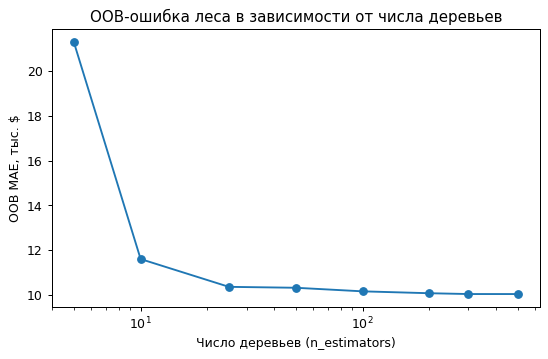

In [8]:
# Число деревьев: как меняется OOB-ошибка с ростом n_estimators (параметры берём из настройки)
bp = {k.replace("model__", ""): v for k, v in search.best_params_.items() if k != "model__n_estimators"}
prep_only = build_preprocessor().fit(X_train)
Xtr_p = prep_only.transform(X_train)
ns = [5, 10, 25, 50, 100, 200, 300, 500]
oob_mae = []
for n in ns:
    m = RandomForestRegressor(n_estimators=n, oob_score=True, random_state=42, **bp).fit(Xtr_p, y_train)
    oob_mae.append(mean_absolute_error(y_train, m.oob_prediction_))
plt.figure(figsize=(7, 4))
plt.plot(ns, oob_mae, marker="o")
plt.xscale("log")
plt.title("OOB-ошибка леса в зависимости от числа деревьев")
plt.xlabel("Число деревьев (n_estimators)")
plt.ylabel("OOB MAE, тыс. $")
plt.show()
print({n: round(float(v), 3) for n, v in zip(ns, oob_mae)})

**Выбор числа деревьев.** OOB-ошибка резко падает до 25 деревьев (21,3 → 10,4 тыс. $), дальше убывает медленно и выходит на плато около 200–300 деревьев (10,07 → 10,03), а после 300 практически не меняется (500 деревьев: 10,03). Поэтому в итоговой модели `n_estimators=300` (так же выбрано перебором): это достаточно, чтобы ошибка стабилизировалась, и не слишком дорого по времени. Больше деревьев лес не переобучает, но и не улучшает качество, а лишь увеличивает время работы.

## 4. Важность признаков
Встроенная (impurity-based) важность считается для столбцов **после** one-hot кодирования; чтобы читать результат по исходным признакам, важности дамми-столбцов одной категории суммируются.

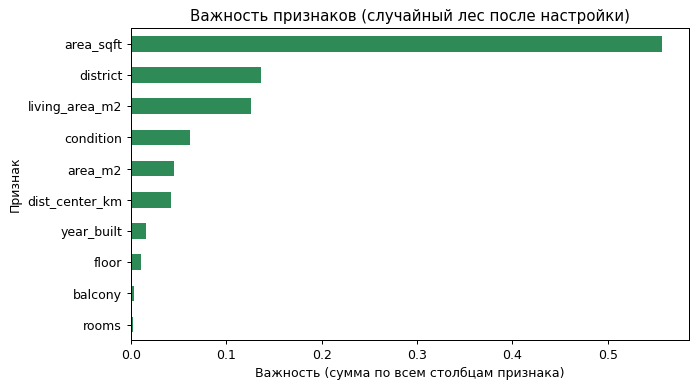

area_sqft         0.557
district          0.136
living_area_m2    0.126
condition         0.062
area_m2           0.045
dist_center_km    0.042
year_built        0.016
floor             0.011
balcony           0.003
rooms             0.002
dtype: float64

In [9]:
def aggregated_importance(pipe):
    names = pipe.named_steps["prep"].get_feature_names_out()
    imp = pipe.named_steps["model"].feature_importances_
    cat_cols = [c for c in CAT_COLS]
    out = {}
    for n, v in zip(names, imp):
        if n.startswith("num__"):
            key = n[len("num__"):]
        else:
            key = next(c for c in cat_cols if n.startswith(f"cat__{c}_"))
        out[key] = out.get(key, 0) + v
    return pd.Series(out).sort_values(ascending=False)

importance = aggregated_importance(rf_tuned)
plt.figure(figsize=(8, 4.5))
importance.sort_values().plot(kind="barh", color="seagreen")
plt.title("Важность признаков (случайный лес после настройки)")
plt.xlabel("Важность (сумма по всем столбцам признака)")
plt.ylabel("Признак")
plt.show()
importance.round(3)

**Вывод по важности.**
- Наибольшую важность имеют признаки площади: `area_sqft` (0,56), `living_area_m2` (0,13), `area_m2` (0,05) — вместе ≈ 0,73. Три признака описывают одну и ту же площадь, и важность «делится» между ними почти произвольно (в ПР-4 мы видели то же в коэффициентах линейной модели). Поэтому важность `area_sqft` в 0,56 не означает, что футы «важнее» метров, — это артефакт коррелирующих признаков.
- Заметные факторы: `district` (0,14), `condition` (0,06), `dist_center_km` (0,04). Остальные — `year_built`, `floor`, `balcony`, `rooms` — имеют важность ≤ 0,016.
- Два самых важных признака: **`area_sqft` и `district`** (если считать площадь одним признаком — **площадь и район**).
- *Оговорки:* встроенная (impurity-based) важность завышает значимость признаков с большим числом уникальных значений (у `area_sqft` их много), и она, как и корреляция, не доказывает причинность.

## 5. Эксперимент: что будет, если убрать наименее важные признаки
Признаки ранжированы по важности; по очереди убираем самые «слабые» и каждый раз заново обучаем лес с подобранными параметрами. Качество смотрим по CV на train (для отбора) и на test (контроль).

In [10]:
order = list(importance.index)                          # от самого важного к наименее важному
best_params = {k.replace("model__", ""): v for k, v in search.best_params_.items()}
rows = []
for k in range(0, 7):
    dropped = order[len(order) - k:] if k else []
    keep = [c for c in order if c not in dropped]
    num = [c for c in NUM_COLS if c in keep]; cat = [c for c in CAT_COLS if c in keep]
    pipe = make_pipe(RandomForestRegressor(random_state=42, **best_params), num, cat)
    cv_mae = -cross_val_score(pipe, X_train, y_train, cv=cv5, scoring="neg_mean_absolute_error").mean()
    pipe.fit(X_train, y_train)
    pred = pipe.predict(X_test)
    rows.append({"убрано признаков": k, "убраны": ", ".join(dropped) or "—", "осталось": len(keep),
                 "CV MAE": cv_mae, "test MAE": mean_absolute_error(y_test, pred), "test R²": r2_score(y_test, pred)})
removal = pd.DataFrame(rows).round(3)
removal

   убрано признаков                                             убраны  осталось  CV MAE  test MAE  test R²
0                 0                                                  —        10  10.143    10.820    0.836
1                 1                                              rooms         9  10.089    10.816    0.837
2                 2                                     balcony, rooms         8  10.093    10.881    0.836
3                 3                              floor, balcony, rooms         7  10.103    10.896    0.838
4                 4                  year_built, floor, balcony, rooms         6  10.054    11.011    0.835
5                 5  dist_center_km, year_built, floor, balcony, rooms         5  10.259    11.200    0.825
6                 6  area_m2, dist_center_km, year_built, floor, ba...         4  10.222    11.166    0.828

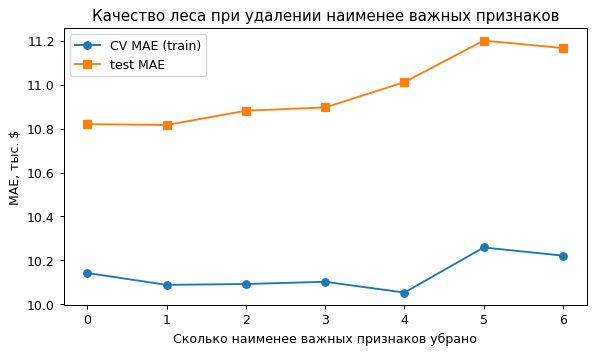

In [11]:
plt.figure(figsize=(7.5, 4))
plt.plot(removal["убрано признаков"], removal["CV MAE"], marker="o", label="CV MAE (train)")
plt.plot(removal["убрано признаков"], removal["test MAE"], marker="s", label="test MAE")
plt.title("Качество леса при удалении наименее важных признаков")
plt.xlabel("Сколько наименее важных признаков убрано")
plt.ylabel("MAE, тыс. $")
plt.legend()
plt.show()

**Вывод эксперимента.**

| Убраны | CV MAE | test MAE |
|---|---|---|
| ничего (10 признаков) | 10,14 | 10,82 |
| `rooms` | 10,09 | 10,82 |
| `rooms`, `balcony` | 10,09 | 10,88 |
| `rooms`, `balcony`, `floor` | 10,10 | 10,90 |
| `rooms`, `balcony`, `floor`, `year_built` | **10,05** | 11,01 |
| + `dist_center_km` | 10,26 | 11,20 |

- Пока убираем `rooms`, `balcony`, `floor`, `year_built`, CV MAE практически не меняется (10,05–10,14), а test MAE растёт не более чем на ≈ 0,2 тыс. $ — это меньше разброса между фолдами (±0,74), то есть **в пределах шума**.
- На пятом шаге, когда убирается `dist_center_km`, качество заметно падает (CV MAE 10,26, test MAE 11,20, R² 0,825): это уже содержательный признак, его убирать нельзя.
- Важно: важность по версии модели ≠ отсутствие эффекта. `balcony` (+3 тыс. $ к цене) и `floor` — реальные, но слабые эффекты, потонувшие в шуме.

## 6. Итоговый вывод

- **Дерево против леса:** одиночное дерево переобучается (train R² = 1,0, test R² = 0,756); лес из 300 деревьев на тех же данных и том же разбиении даёт test R² ≈ 0,84 и снижает MAE с 13,1 до ≈ 10,8 тыс. $.
- **Число деревьев:** `n_estimators=300` — OOB-ошибка выходит на плато в районе 200–300 деревьев.
- **Настройка** (`max_depth=10`, `min_samples_leaf=3`) заметного выигрыша не дала: лес по умолчанию и так близок к оптимуму — это нормально для случайного леса.
- **Какие признаки можно исключить без потери качества:** `rooms`, `balcony`, `floor`, `year_built` — разница в качестве в пределах шума. **Нельзя исключать:** признаки площади, `district`, `condition`, `dist_center_km`.
- **На этих данных линейная регрессия лучше леса** (MAE 8,8 против 10,6 тыс. $), потому что зависимость в них линейная — всегда полезно сравнивать с простой базовой моделью.
- Важность признаков в лесу нельзя трактовать как причинно-следственную связь, а для коррелирующих признаков (три вида площади) она делится между ними произвольно.